<div style="background: linear-gradient(135deg, #003366 0%, #0055a5 100%); border-radius: 12px; padding: 18px 26px; display: flex; align-items: center; gap: 24px; box-shadow: 0 4px 12px rgba(0,0,0,0.2);">
    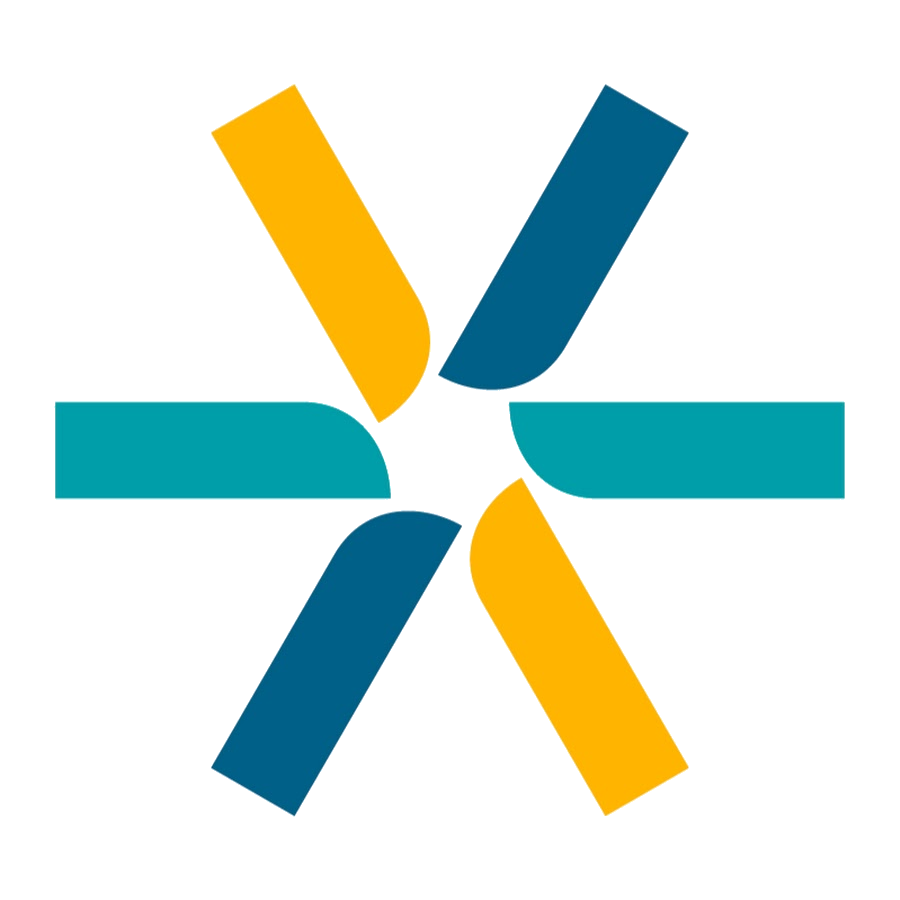
    <div>
        <h1 style="margin: 0; color: #ffffff; font-size: 1.45em; letter-spacing: 0.5px;">Aprendizaje Automático y Grandes Datos</h1>
        <h2 style="margin: 6px 0 2px 0; color: #cce4ff; font-size: 1.15em; font-weight: normal;">Detección de anomalías · demanda eléctrica (CAMMESA)</h2>
        <h3 style="margin: 0 0 8px 0; color: #a8d0f5; font-size: 1em; font-weight: normal;">Unidad 8 · Aprendizaje no supervisado</h3>
        <span style="background: #ffd700; color: #003366; font-weight: bold; font-size: 0.9em; padding: 3px 12px; border-radius: 20px;">⚡ Grupo 6 · Clase 46 sobre nuestro dataset</span>
    </div>
</div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Antes de empezar</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La pregunta</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">¿Qué agente del mercado eléctrico <b>no se parece a ninguno</b>? Lo raro ya apareció como ruido de DBSCAN en la clase 43. Acá aparece como tarea de aprendizaje: un modelo aprende qué es lo normal y puntúa cuánto se aleja cada fila. Después, un umbral.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los datos</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Los 868 perfiles de agentes de las clases 41 y 43 (seis números por serie, escalados: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">Z</code>). No tienen etiqueta de anomalía: nadie dijo cuáles son raros. Por eso también hay datos <b>construidos</b>, dichos en cada celda e idénticos a la cátedra: los diez valores de tráfico de Amr y dos nubes con 20 anomalías esparcidas (con etiqueta, para evaluar). Y un agente inventado que está dentro del rango de cada columna y lejos de la relación entre ellas.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se quiere resolver</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Umbral por columna como estimador; por qué una columna no alcanza y la envolvente elíptica; anomalía contra novedad; por densidad (mezcla de gaussianas, factor local, el ruido de DBSCAN); por aislamiento (el bosque a mano y con la biblioteca); cómo se evalúa con etiquetas y qué se puede hacer sin ellas; y cuál para qué.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se muestra</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas secciones de la clase 46: 1 · los datos → A · qué es raro → B · por densidad → C · por aislamiento → D · cuál para qué → E · usarlo: los agentes más raros por consenso, y dos agentes nuevos.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cómo se decide</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Todos devuelven un puntaje continuo (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">score_samples</code>; en LOF, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">negative_outlier_factor_</code>): más bajo, más raro. El umbral lo pone la proporción de raros que se espera o el costo de cada error. Con etiquetas (solo en lo construido): AUC, precisión y exhaustividad. Sin etiquetas: cuánto coinciden los métodos, y mirar los casos.</td></tr></table></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué hay que saber antes de buscar raros en estos datos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Sobre los agentes no hay verdad:</b> no se puede decir qué método acertó. Lo que se ve es que los métodos coinciden en los extremos y discrepan en el borde, y que los raros por consenso son, casi todos, el ruido de DBSCAN de la clase 43: grandes usuarios muy volátiles (varios de petroleras), y algunos agentes extremos en estacionalidad o en tendencia.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Los umbrales por defecto de la biblioteca no son una proporción:</b> <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">IsolationForest</code> con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">contamination="auto"</code> corta el puntaje en −0,5, como el paper original, y marca una fracción que depende de los datos. Lo que se hace en todo el cuaderno es cortar el puntaje por percentil, con la proporción que se decide (2 %: 17 agentes).</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las precisiones y exhaustividades son sobre las dos nubes construidas, donde las 20 anomalías se plantaron lejos a propósito.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">1 · Los datos: los agentes, y dos nubes con anomalías plantadas</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Los perfiles escalados; dos nubes construidas con 20 anomalías lejos de ellas</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">Z</code> como en las clases 41 y 43. Y los datos construidos para evaluar, igual que en la cátedra: dos nubes gaussianas (980 puntos) y 20 anomalías a más de 3,5 desvíos de los dos centros, con etiqueta 1.</p></div>

868 agentes · 6 columnas escaladas · sin etiqueta de anomalía · el 2 % son 17


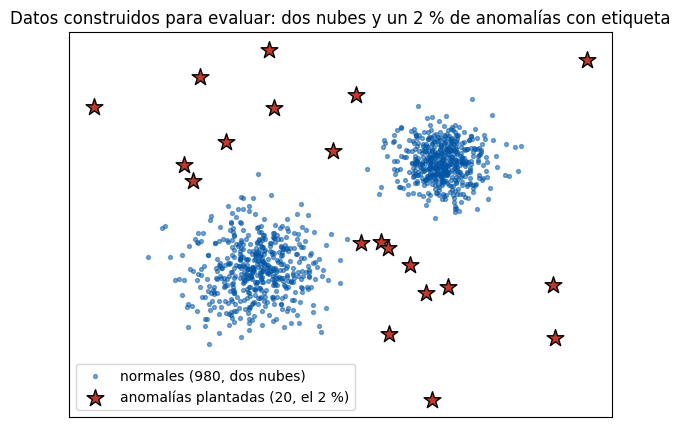

Construidas: 1000 filas, 20 anomalías (2 %)


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import EllipticEnvelope
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, precision_recall_curve
import warnings; warnings.filterwarnings("ignore")

AZUL, AMBAR, GRIS, ROJO, VERDE, VIOLETA = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57", "#7c3aed"
pd.set_option("display.width", 140)
np.set_printoptions(suppress=True, precision=3)

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
demanda = demanda.sort_values(["serie", "periodo"])
def perfil(g):
    """Los seis números de la clase 41."""
    s = g.set_index("periodo")["demanda_MWh"]
    if len(s) < 24 or (s <= 0).mean() > 0.1:
        return None
    pos = s[s > 0]
    cambio = (s / s.shift(1) - 1)[s.shift(1) > 0].clip(-1, 3)
    mes = pos.index.month
    verano, invierno = pos[np.isin(mes, [12, 1, 2])].mean(), pos[np.isin(mes, [6, 7, 8])].mean()
    anios = np.array([(p - pos.index[0]).n for p in pos.index]) / 12
    return pd.Series({"log_tamano": np.log10(pos.mean()), "estacionalidad": np.log2(verano / invierno),
                      "volatilidad": cambio.abs().median(), "tendencia_anual": np.polyfit(anios, np.log10(pos.to_numpy()), 1)[0],
                      "frac_caidas": (cambio < -0.15).mean(), "cv": pos.std() / pos.mean()})
perfiles = demanda.groupby("serie").apply(perfil).dropna()
COLUMNAS = ["log_tamano", "estacionalidad", "volatilidad", "tendencia_anual", "frac_caidas", "cv"]
tarifa = demanda.groupby("serie")["categoria_tarifa"].first().loc[perfiles.index]
escalador = StandardScaler().fit(perfiles[COLUMNAS])
Z = escalador.transform(perfiles[COLUMNAS])
N = len(Z); RAROS = int(round(0.02 * N))
print(f"{N} agentes · {Z.shape[1]} columnas escaladas · sin etiqueta de anomalía · el 2 % son {RAROS}")

rng = np.random.default_rng(2026)
X_nubes, y_nubes = make_blobs(n_samples=980, centers=[[0, 0], [6, 4]], cluster_std=[1.0, 0.7], random_state=2026)  # datos construidos
candidatas = rng.uniform([-5, -5], [11, 9], size=(400, 2))
lejos = (np.linalg.norm(candidatas - [0, 0], axis=1) / 1.0 > 3.5) & (np.linalg.norm(candidatas - [6, 4], axis=1) / 0.7 > 3.5)
anomalias = candidatas[lejos][:20]
X2 = np.vstack([X_nubes, anomalias]); y2 = np.r_[np.zeros(980, dtype=int), np.ones(20, dtype=int)]                   # 1 = anomalía (solo para evaluar)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_nubes[:, 0], X_nubes[:, 1], s=8, alpha=0.5, color=AZUL, label="normales (980, dos nubes)")
ax.scatter(anomalias[:, 0], anomalias[:, 1], marker="*", s=160, color=ROJO, edgecolor="black", label="anomalías plantadas (20, el 2 %)")
ax.legend(); ax.set_xticks([]); ax.set_yticks([]); ax.set_title("Datos construidos para evaluar: dos nubes y un 2 % de anomalías con etiqueta")
plt.show()
print(f"Construidas: {len(X2)} filas, {y2.sum()} anomalías ({100 * y2.mean():.0f} %)")

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">A · Qué es raro: umbrales, la elipse, anomalía y novedad</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.1 · Con estadística básica: un umbral es un estimador</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Los diez valores de tráfico del material, igual que en la cátedra.</p></div>

media 167.0 · desvío 119.4 · media + 2 desvíos = 405.8 · percentil 95 = 363.2
El 500 está a 2.79 desvíos; el 196, a 0.24: con la media inflada por el 500 y el desvío de 119, el 196 no llega
UmbralPercentil(0.95): umbral_ = 363.2 · predict: [1, 1, 1, 1, 1, 1, 1, 1, -1, 1] · atípicos: [500]


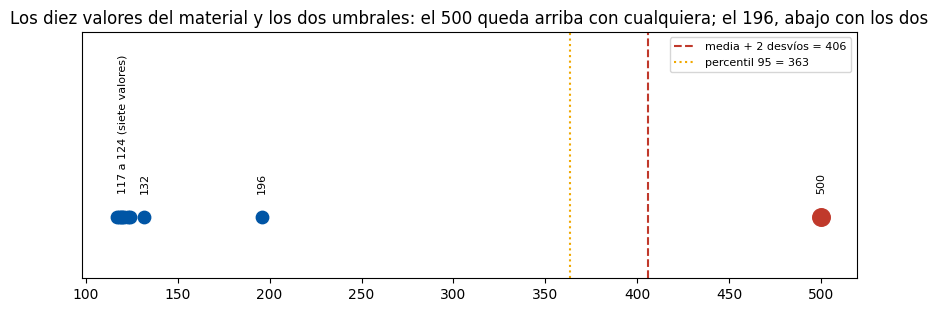

In [2]:
trafico = np.array([120, 123, 124, 119, 196, 121, 118, 117, 500, 132])                     # los diez valores del material
media, desvio = trafico.mean(), trafico.std(ddof=1)
umbral_desvios, umbral_percentil = media + 2 * desvio, np.quantile(trafico, 0.95)
print(f"media {media:.1f} · desvío {desvio:.1f} · media + 2 desvíos = {umbral_desvios:.1f} · percentil 95 = {umbral_percentil:.1f}")
print(f"El 500 está a {(500 - media) / desvio:.2f} desvíos; el 196, a {(196 - media) / desvio:.2f}: con la media inflada por el 500 y el desvío de 119, el 196 no llega")
class UmbralPercentil:
    """Un detector de una columna: fit guarda el umbral, predict compara. −1 atípico, 1 normal (la convención de la biblioteca)."""
    def __init__(self, q=0.95): self.q = q
    def fit(self, x, y=None): self.umbral_ = np.quantile(x, self.q); return self                 # fit ignora cualquier y
    def predict(self, x): return np.where(x > self.umbral_, -1, 1)
detector = UmbralPercentil(0.95).fit(trafico)
print(f"UmbralPercentil(0.95): umbral_ = {detector.umbral_:.1f} · predict: {detector.predict(trafico).tolist()} · atípicos: {trafico[detector.predict(trafico) == -1].tolist()}")
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.scatter(trafico, np.zeros(10), s=80, color=AZUL, zorder=3); ax.scatter([500], [0], s=160, color=ROJO, zorder=4)
for v in [132, 196, 500]: ax.text(v, 0.02, str(v), ha="center", fontsize=8, rotation=90)
ax.text(120, 0.02, "117 a 124 (siete valores)", ha="center", fontsize=8, rotation=90)
ax.axvline(umbral_desvios, color=ROJO, ls="--", label=f"media + 2 desvíos = {umbral_desvios:.0f}"); ax.axvline(umbral_percentil, color=AMBAR, ls=":", label=f"percentil 95 = {umbral_percentil:.0f}")
ax.set_yticks([]); ax.set_ylim(-0.05, 0.15); ax.legend(fontsize=8); ax.set_title("Los diez valores del material y los dos umbrales: el 500 queda arriba con cualquiera; el 196, abajo con los dos")
plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.2 · Una columna no alcanza: la envolvente elíptica</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Un agente construido que está dentro del rango de cada columna y lejos de la <b>relación</b> entre ellas. La volatilidad y la frecuencia de caídas van juntas (correlación ~0,7): un agente con volatilidad alta tiene muchas caídas. El construido tiene una volatilidad del percentil 95 y <b>ninguna</b> caída fuerte: ningún umbral por columna lo ve; la elipse sobre esas dos columnas sí. Y la figura de la diapositiva con las nubes construidas.</p></div>

Correlación entre volatilidad y frecuencia de caídas: 0.77
Agente construido: volatilidad 0.24 (percentil 95), caídas fuertes 0 (percentil 0; el 12 % de los agentes nunca cayó fuerte): ningún umbral por columna lo marca
Envolvente elíptica (2 %): predict del agente construido = -1 · su distancia de Mahalanobis 94.4 contra el umbral 56.4 (el 2 % más lejano de los 868: 18 agentes)


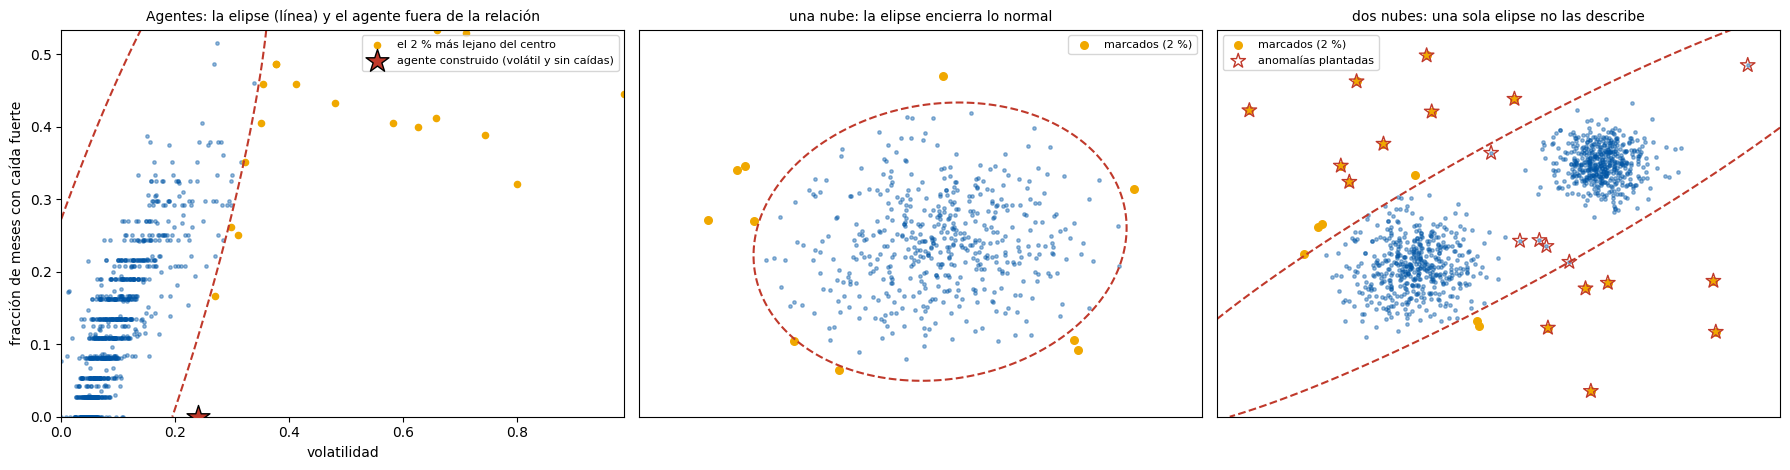

Dos nubes construidas, elipse al 2 %: marca 20 · de las 20 anomalías atrapa 14 · y marca 6 normales del borde


In [3]:
dos = perfiles[["volatilidad", "frac_caidas"]].to_numpy()
print(f"Correlación entre volatilidad y frecuencia de caídas: {np.corrcoef(dos.T)[0, 1]:.2f}")
raro = np.array([[np.percentile(dos[:, 0], 95), 0.0]])                                     # construido: volatilidad del percentil 95 y ninguna caída fuerte
pct = [(dos[:, j] < raro[0, j]).mean() * 100 for j in range(2)]
print(f"Agente construido: volatilidad {raro[0, 0]:.2f} (percentil {pct[0]:.0f}), caídas fuertes 0 (percentil {pct[1]:.0f}; el {100 * (dos[:, 1] == 0).mean():.0f} % de los agentes nunca cayó fuerte): ningún umbral por columna lo marca")
elipse = EllipticEnvelope(contamination=0.02, random_state=2026).fit(dos)
print(f"Envolvente elíptica (2 %): predict del agente construido = {int(elipse.predict(raro)[0])} · su distancia de Mahalanobis {elipse.mahalanobis(raro)[0]:.1f} contra el umbral {-elipse.offset_:.1f} (el 2 % más lejano de los {N}: {(elipse.predict(dos) == -1).sum()} agentes)")
fig, ejes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = ejes[0]; ax.scatter(dos[:, 0], dos[:, 1], s=6, alpha=0.4, color=AZUL); ax.scatter(dos[elipse.predict(dos) == -1, 0], dos[elipse.predict(dos) == -1, 1], s=20, color=AMBAR, label="el 2 % más lejano del centro")
ax.scatter(raro[:, 0], raro[:, 1], marker="*", s=300, color=ROJO, edgecolor="black", zorder=5, label="agente construido (volátil y sin caídas)")
xx, yy = np.meshgrid(np.linspace(dos[:, 0].min(), dos[:, 0].max(), 150), np.linspace(dos[:, 1].min(), dos[:, 1].max(), 150))
ax.contour(xx, yy, elipse.mahalanobis(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), levels=[-elipse.offset_], colors=ROJO, linestyles="--")
ax.set_xlabel("volatilidad"); ax.set_ylabel("fracción de meses con caída fuerte"); ax.legend(fontsize=8); ax.set_title("Agentes: la elipse (línea) y el agente fuera de la relación", fontsize=10)
for ax, X_, titulo in [(ejes[1], X_nubes[y_nubes == 0], "una nube: la elipse encierra lo normal"), (ejes[2], X2, "dos nubes: una sola elipse no las describe")]:
    e_ = EllipticEnvelope(contamination=0.02, random_state=2026).fit(X_); marcados = e_.predict(X_) == -1
    ax.scatter(X_[:, 0], X_[:, 1], s=6, alpha=0.4, color=AZUL); ax.scatter(X_[marcados, 0], X_[marcados, 1], s=30, color=AMBAR, label="marcados (2 %)")
    if X_ is X2: ax.scatter(anomalias[:, 0], anomalias[:, 1], marker="*", s=120, facecolors="none", edgecolors=ROJO, label="anomalías plantadas")
    xx, yy = np.meshgrid(np.linspace(X_[:, 0].min() - 1, X_[:, 0].max() + 1, 150), np.linspace(X_[:, 1].min() - 1, X_[:, 1].max() + 1, 150))
    ax.contour(xx, yy, e_.mahalanobis(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), levels=[-e_.offset_], colors=ROJO, linestyles="--")
    ax.set_xticks([]); ax.set_yticks([]); ax.legend(fontsize=8); ax.set_title(titulo, fontsize=10)
plt.tight_layout(); plt.show()
e2 = EllipticEnvelope(contamination=0.02, random_state=2026).fit(X2); m2 = e2.predict(X2) == -1
print(f"Dos nubes construidas, elipse al 2 %: marca {m2.sum()} · de las 20 anomalías atrapa {m2[y2 == 1].sum()} · y marca {m2[y2 == 0].sum()} normales del borde")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El agente construido no es extremo en ninguna columna sola: hay agentes con esa volatilidad, y el 12 % de los agentes nunca cayó fuerte. Lo raro es la combinación: con esa volatilidad, casi todos los agentes caen seguido. La elipse lo mide como distancia al centro en la dirección de la relación. Pero sobre los agentes la elipse también marca a los del extremo superior de la nube (muy volátiles y con muchas caídas): para ella, lo raro es estar lejos del centro, en cualquier dirección.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.3 · Anomalía y novedad</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Atípicos: ajustar y predecir sobre los mismos datos mezclados (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">fit_predict</code>). Novedad: ajustar solo sobre datos limpios y predecir sobre datos nuevos (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">fit</code> y después <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict</code>). Se arma un conjunto «limpio» (los agentes sin el 2 % más raro según el factor local) y se predicen los dos agentes nuevos de la clase 43: el comercio típico y el extremo.</p></div>

In [4]:
lof_atipicos = LocalOutlierFactor(n_neighbors=50)                                           # novelty=False (defecto): detección de atípicos
etiquetas_lof = lof_atipicos.fit_predict(Z)                                                   # fit_predict sobre los datos mezclados; no hay predict
puntaje_lof = lof_atipicos.negative_outlier_factor_
limpio = Z[puntaje_lof >= np.percentile(puntaje_lof, 2)]                                     # sin el 2 % más raro
print(f"Atípicos: fit_predict sobre los {N} · con contamination=\"auto\" marca {(etiquetas_lof == -1).sum()} · conjunto limpio para novedad: {len(limpio)} agentes")
nuevos = pd.DataFrame([{"log_tamano": np.log10(800), "estacionalidad": np.log2(1.4), "volatilidad": 0.12, "tendencia_anual": np.log10(1.03), "frac_caidas": 1 / 6, "cv": 0.25},
                       {"log_tamano": np.log10(300), "estacionalidad": np.log2(3.5), "volatilidad": 0.45, "tendencia_anual": np.log10(0.70), "frac_caidas": 0.40, "cv": 1.2}])[COLUMNAS]
z_nuevos = escalador.transform(nuevos)
lof_novedad = LocalOutlierFactor(n_neighbors=50, novelty=True).fit(limpio)                   # novelty=True: fit sobre lo limpio, predict sobre lo nuevo
ocsvm = OneClassSVM(nu=0.02).fit(limpio)                                                      # nu: cota de la fracción de atípicos de entrenamiento
for i, nombre_ in enumerate(["agente 1 (comercio típico)", "agente 2 (extremo en todo)"]):
    print(f"{nombre_}: LOF novedad → {int(lof_novedad.predict(z_nuevos[[i]])[0])} (puntaje {lof_novedad.score_samples(z_nuevos[[i]])[0]:.2f}) · One-class SVM → {int(ocsvm.predict(z_nuevos[[i]])[0])} (puntaje {ocsvm.score_samples(z_nuevos[[i]])[0]:.2f})")
print("−1 es atípico, 1 es normal, en todos los detectores de la biblioteca. fit ignora cualquier y.")

Atípicos: fit_predict sobre los 868 · con contamination="auto" marca 86 · conjunto limpio para novedad: 850 agentes
agente 1 (comercio típico): LOF novedad → 1 (puntaje -1.05) · One-class SVM → 1 (puntaje 0.86)
agente 2 (extremo en todo): LOF novedad → -1 (puntaje -2.17) · One-class SVM → -1 (puntaje 0.17)
−1 es atípico, 1 es normal, en todos los detectores de la biblioteca. fit ignora cualquier y.


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">B · Por densidad: mezcla de gaussianas, factor local, el ruido</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.1 · Baja densidad: la mezcla de gaussianas y el 2 %</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sobre las dos nubes construidas, como en la cátedra. Sobre los agentes: cuántas gaussianas (por BIC) y el 2 % menos denso.</p></div>

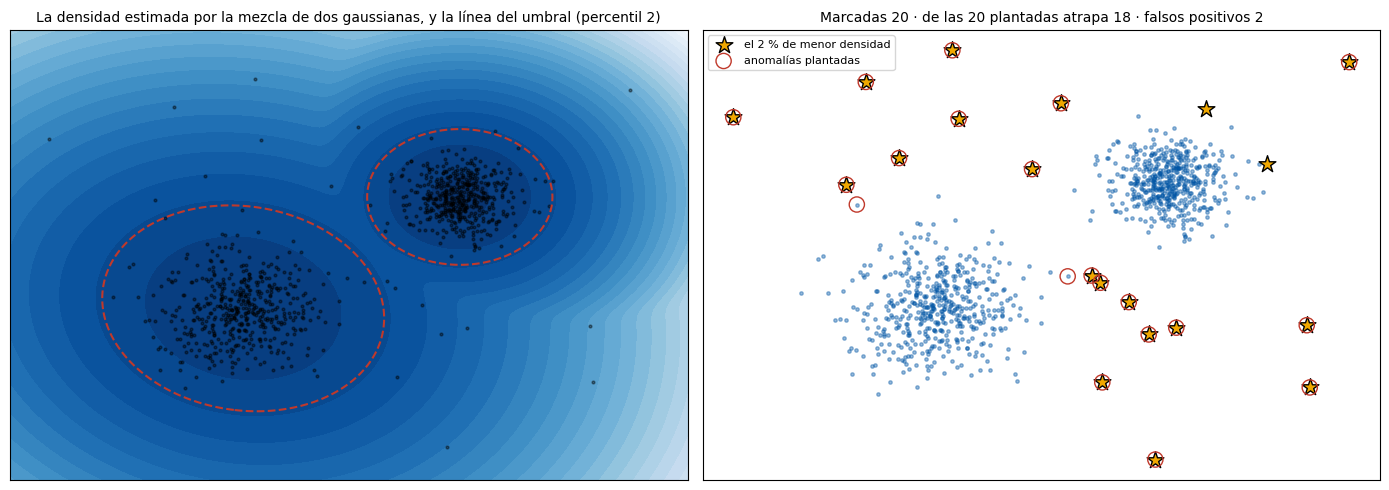

Precisión 0.90 · exhaustividad 0.90 con el umbral en el 2 % · pesos de las dos gaussianas [0.49, 0.51], centros [[6.0, 4.1], [0.2, 0.1]]
Agentes · BIC por cantidad de gaussianas (menor es mejor): {1: 13490, 2: 9998, 3: 9200, 4: 9026, 5: 8806, 6: 8774} → 6 gaussianas · el 2 % menos denso: 18 agentes con log-densidad < -14.6


In [5]:
mezcla = GaussianMixture(n_components=2, random_state=2026).fit(X2)
log_densidad = mezcla.score_samples(X2); umbral = np.percentile(log_densidad, 2)
marcadas = log_densidad < umbral
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))
xx, yy = np.meshgrid(np.linspace(-6, 12, 200), np.linspace(-6, 10, 200)); dens = mezcla.score_samples(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
a.contourf(xx, yy, dens, levels=30, cmap="Blues"); a.contour(xx, yy, dens, levels=[umbral], colors=ROJO, linestyles="--"); a.scatter(X2[:, 0], X2[:, 1], s=4, color="black", alpha=0.4)
a.set_title("La densidad estimada por la mezcla de dos gaussianas, y la línea del umbral (percentil 2)", fontsize=10); a.set_xticks([]); a.set_yticks([])
b.scatter(X2[:, 0], X2[:, 1], s=6, alpha=0.4, color=AZUL); b.scatter(X2[marcadas, 0], X2[marcadas, 1], marker="*", s=160, color=AMBAR, edgecolor="black", label="el 2 % de menor densidad")
b.scatter(anomalias[:, 0], anomalias[:, 1], marker="o", s=120, facecolors="none", edgecolors=ROJO, label="anomalías plantadas"); b.legend(fontsize=8); b.set_xticks([]); b.set_yticks([])
b.set_title(f"Marcadas {marcadas.sum()} · de las 20 plantadas atrapa {marcadas[y2 == 1].sum()} · falsos positivos {marcadas[y2 == 0].sum()}", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Precisión {precision_score(y2, marcadas):.2f} · exhaustividad {recall_score(y2, marcadas):.2f} con el umbral en el 2 % · pesos de las dos gaussianas {mezcla.weights_.round(2).tolist()}, centros {mezcla.means_.round(1).tolist()}")
bics = {k: GaussianMixture(n_components=k, n_init=3, random_state=2026).fit(Z).bic(Z) for k in range(1, 7)}
k_mejor = min(bics, key=bics.get); mezcla_socios = GaussianMixture(n_components=k_mejor, n_init=3, random_state=2026).fit(Z)
puntaje_mezcla = mezcla_socios.score_samples(Z)
bics_r = {k: round(v) for k, v in bics.items()}
print(f"Agentes · BIC por cantidad de gaussianas (menor es mejor): {bics_r} → {k_mejor} gaussianas · el 2 % menos denso: {(puntaje_mezcla < np.percentile(puntaje_mezcla, 2)).sum()} agentes con log-densidad < {np.percentile(puntaje_mezcla, 2):.1f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.2 · El factor local de atipicidad</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La figura de la diapositiva con las nubes construidas, y el factor sobre los agentes.</p></div>

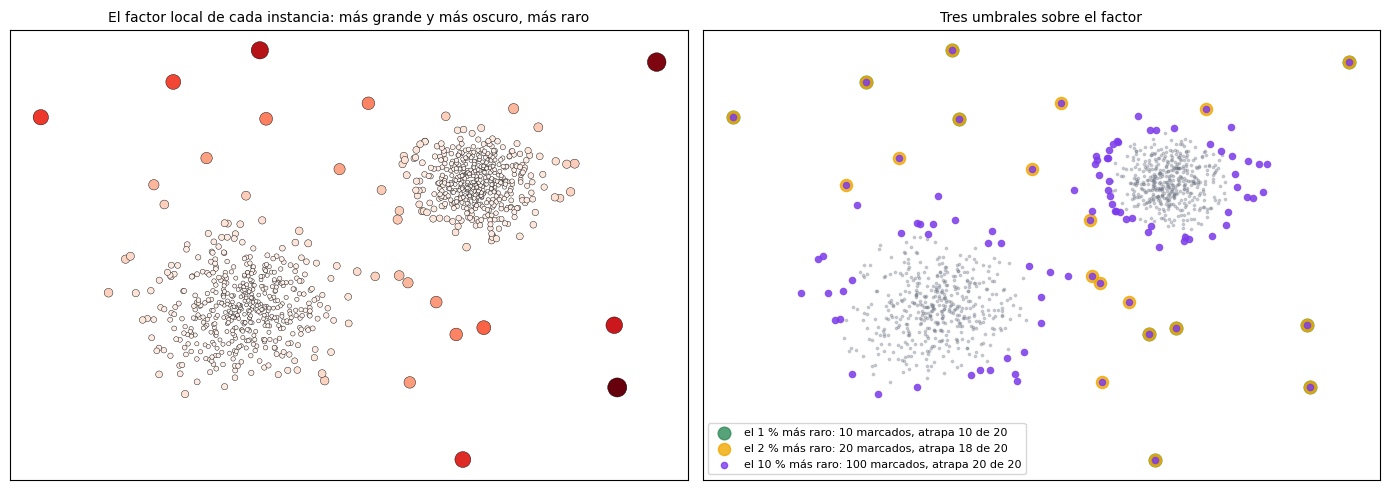

,umbral,marcados,anomalías atrapadas,precisión,exhaustividad
0,1 % más raro,10,10,1.0,0.5
1,2 % más raro,20,18,0.9,0.9
2,10 % más raro,100,20,0.2,1.0


Agentes · factor local (k = 50): el 2 % más raro tiene factor > 2.34 · el más raro de todos: factor 3.85, AYSABECY | GUMAS/AUTOGENERADORES · mediana 1.10


In [6]:
lof2 = LocalOutlierFactor(n_neighbors=50).fit(X2); factor = -lof2.negative_outlier_factor_      # el factor, positivo: 1 normal, más grande más raro
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))
a.scatter(X2[:, 0], X2[:, 1], s=8 + 30 * (factor - 1), c=factor, cmap="Reds", edgecolor="black", linewidths=0.3); a.set_xticks([]); a.set_yticks([])
a.set_title("El factor local de cada instancia: más grande y más oscuro, más raro", fontsize=10)
filas = []
for q, color in [(1, VERDE), (2, AMBAR), (10, VIOLETA)]:
    marcados = factor > np.percentile(factor, 100 - q)
    b.scatter(X2[marcados, 0], X2[marcados, 1], s=90 - 7 * q, color=color, alpha=0.8, label=f"el {q} % más raro: {marcados.sum()} marcados, atrapa {marcados[y2 == 1].sum()} de 20")
    filas.append({"umbral": f"{q} % más raro", "marcados": int(marcados.sum()), "anomalías atrapadas": int(marcados[y2 == 1].sum()), "precisión": precision_score(y2, marcados), "exhaustividad": recall_score(y2, marcados)})
b.scatter(X2[:, 0], X2[:, 1], s=3, color=GRIS, alpha=0.3, zorder=0); b.legend(fontsize=8); b.set_xticks([]); b.set_yticks([]); b.set_title("Tres umbrales sobre el factor", fontsize=10)
plt.tight_layout(); plt.show()
display(pd.DataFrame(filas).round(2))
print(f"Agentes · factor local (k = 50): el 2 % más raro tiene factor > {np.percentile(-puntaje_lof, 98):.2f} · el más raro de todos: factor {(-puntaje_lof).max():.2f}, {perfiles.index[int(np.argmax(-puntaje_lof))]} · mediana {np.median(-puntaje_lof):.2f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.3 · El ruido ya era anomalía</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">DBSCAN con eps 1,5 sobre los agentes (clase 43) dejó 56 series de ruido sin buscar anomalías. Se compara con el 2 % más raro de cada método (17 agentes): cuántos están en el ruido.</p></div>

In [7]:
ruido = DBSCAN(eps=1.5, min_samples=5).fit_predict(Z) == -1
puntajes = {"elipse": EllipticEnvelope(random_state=2026).fit(Z).score_samples(Z), "mezcla": puntaje_mezcla, "factor local": puntaje_lof}
top = {n: set(np.argsort(p)[:RAROS]) for n, p in puntajes.items()}                            # el 2 % más raro: los 17 de menor puntaje
print(f"Ruido de DBSCAN (clase 43): {ruido.sum()} agentes")
for n, t in top.items(): print(f"   el 2 % más raro según {n}: {len(t)} agentes, de los que {sum(ruido[list(t)])} están en el ruido de DBSCAN")
print("Agrupar y detectar son la misma mirada sobre la densidad, con la pregunta al revés: no qué se junta, qué queda solo.")

Ruido de DBSCAN (clase 43): 56 agentes
   el 2 % más raro según elipse: 17 agentes, de los que 17 están en el ruido de DBSCAN
   el 2 % más raro según mezcla: 17 agentes, de los que 17 están en el ruido de DBSCAN
   el 2 % más raro según factor local: 17 agentes, de los que 17 están en el ruido de DBSCAN
Agrupar y detectar son la misma mirada sobre la densidad, con la pregunta al revés: no qué se junta, qué queda solo.


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">C · Por aislamiento: el bosque</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.1 · Un árbol al azar, a mano: pocos cortes</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sobre las nubes construidas, igual que en la cátedra.</p></div>

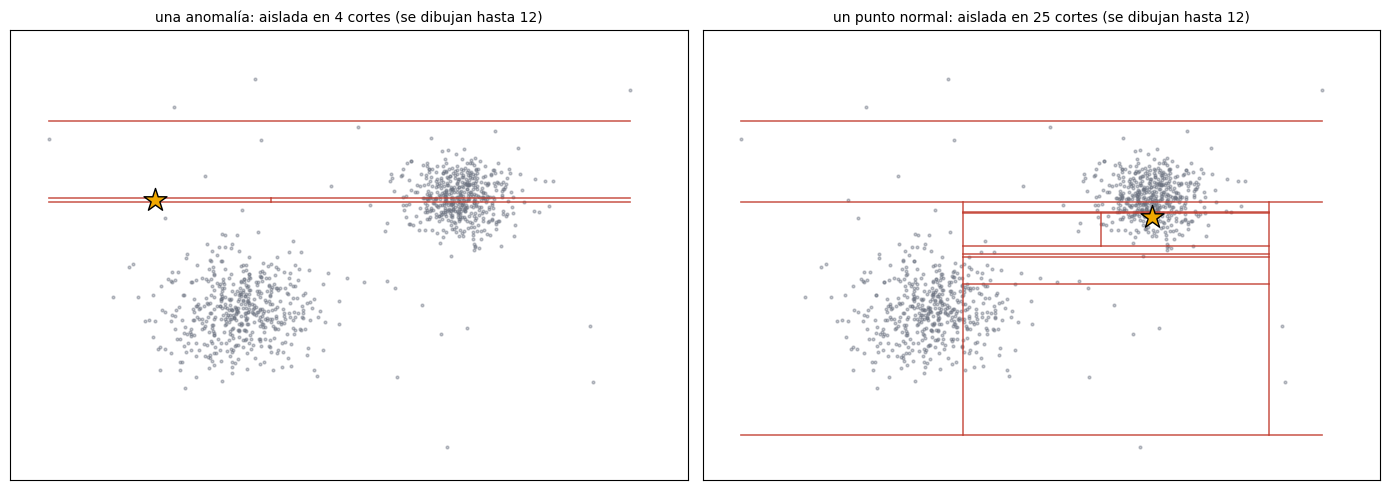

Profundidad media sobre 100 árboles al azar · la anomalía: 8.1 cortes · el punto normal: 19.4 cortes. Menor profundidad, más raro: ese es el puntaje del bosque.


In [8]:
def aislar(X, x, rng, cortes=None, profundidad=0, caja=None):
    """Cortes al azar hasta dejar sola a x. Devuelve la profundidad (cantidad de cortes); guarda los cortes para dibujar."""
    if caja is None: caja = [X[:, 0].min(), X[:, 0].max(), X[:, 1].min(), X[:, 1].max()]
    if len(X) <= 1 or profundidad > 60: return profundidad
    j = rng.integers(X.shape[1]); lo, hi = X[:, j].min(), X[:, j].max()                     # 1. atributo al azar
    if lo == hi: return profundidad
    u = rng.uniform(lo, hi)                                                                   # 2. umbral al azar entre el mínimo y el máximo
    if cortes is not None: cortes.append((j, u, list(caja)))
    lado = X[:, j] < u if x[j] < u else X[:, j] >= u                                          # 3. partir, y seguir del lado de x
    nueva = list(caja); nueva[2 * j + (1 if x[j] < u else 0)] = u
    return aislar(X[lado], x, rng, cortes, profundidad + 1, nueva)                            # 4. contar

i_anom, i_normal = 980, 0                                                                     # una anomalía plantada y un punto de la nube
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax, i, nombre_ in [(ejes[0], i_anom, "una anomalía"), (ejes[1], i_normal, "un punto normal")]:
    cortes = []; prof = aislar(X2, X2[i], np.random.default_rng(28), cortes)                          # la semilla 28 da un árbol ilustrativo; el promedio de 100 está abajo
    ax.scatter(X2[:, 0], X2[:, 1], s=4, color=GRIS, alpha=0.4)
    for k_, (j, u, caja) in enumerate(cortes[:12]):
        if j == 0: ax.plot([u, u], [caja[2], caja[3]], color=ROJO, lw=1.2, alpha=0.8)
        else: ax.plot([caja[0], caja[1]], [u, u], color=ROJO, lw=1.2, alpha=0.8)
    ax.scatter(X2[i, 0], X2[i, 1], marker="*", s=300, color=AMBAR, edgecolor="black", zorder=5)
    ax.set_xlim(-6, 12); ax.set_ylim(-6, 10); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{nombre_}: aislada en {prof} cortes (se dibujan hasta 12)", fontsize=10)
plt.tight_layout(); plt.show()
prof_anom = np.mean([aislar(X2, X2[i_anom], np.random.default_rng(s)) for s in range(100)]); prof_normal = np.mean([aislar(X2, X2[i_normal], np.random.default_rng(s)) for s in range(100)])
print(f"Profundidad media sobre 100 árboles al azar · la anomalía: {prof_anom:.1f} cortes · el punto normal: {prof_normal:.1f} cortes. Menor profundidad, más raro: ese es el puntaje del bosque.")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.2 · El bosque de aislamiento con la biblioteca</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">IsolationForest(n_estimators=200)</code>: sobre las nubes construidas, y sobre los agentes, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict</code> con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">contamination="auto"</code> contra el corte por percentil.</p></div>

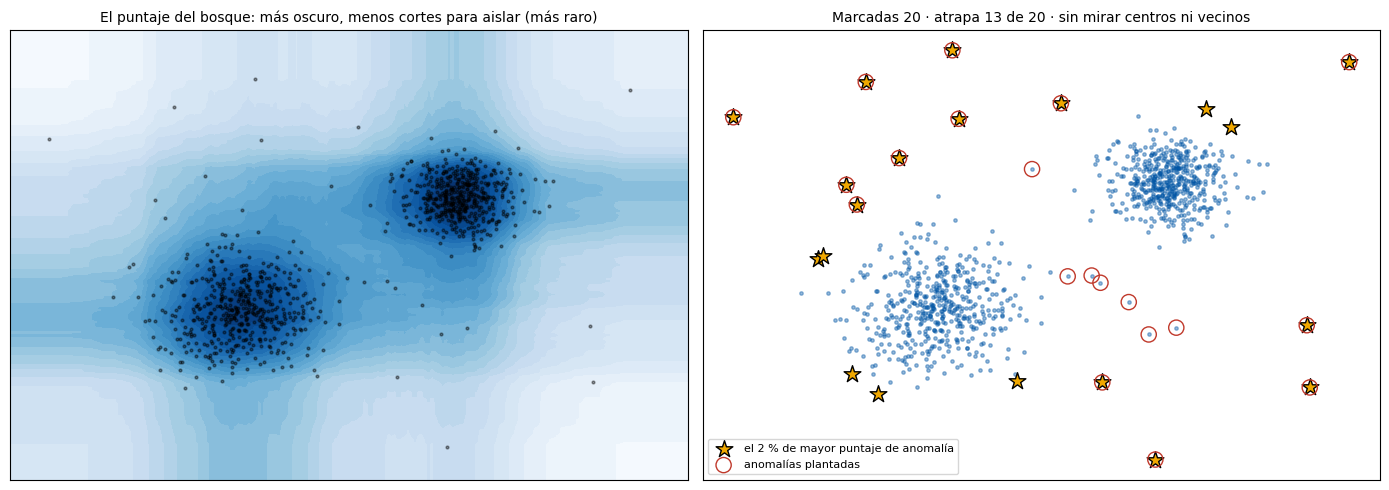

200 árboles en 590 ms · precisión 0.65 · exhaustividad 0.65 · puntaje de la anomalía 980: -0.647 · del normal 0: -0.408
Agentes · predict con contamination="auto": 86 marcados con −1 (10 %: el umbral es puntaje < -0.5, como en el paper, no una proporción) · cortando el puntaje en el percentil 2: 18 agentes


In [9]:
t0 = time.perf_counter(); bosque = IsolationForest(n_estimators=200, random_state=2026, n_jobs=-1).fit(X2); t_b = time.perf_counter() - t0
puntaje_bosque = bosque.score_samples(X2); marcadas_b = puntaje_bosque < np.percentile(puntaje_bosque, 2)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))
mapa = bosque.score_samples(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
a.contourf(xx, yy, mapa, levels=30, cmap="Blues"); a.scatter(X2[:, 0], X2[:, 1], s=4, color="black", alpha=0.4); a.set_xticks([]); a.set_yticks([])
a.set_title("El puntaje del bosque: más oscuro, menos cortes para aislar (más raro)", fontsize=10)
b.scatter(X2[:, 0], X2[:, 1], s=6, alpha=0.4, color=AZUL); b.scatter(X2[marcadas_b, 0], X2[marcadas_b, 1], marker="*", s=160, color=AMBAR, edgecolor="black", label="el 2 % de mayor puntaje de anomalía")
b.scatter(anomalias[:, 0], anomalias[:, 1], marker="o", s=120, facecolors="none", edgecolors=ROJO, label="anomalías plantadas"); b.legend(fontsize=8); b.set_xticks([]); b.set_yticks([])
b.set_title(f"Marcadas {marcadas_b.sum()} · atrapa {marcadas_b[y2 == 1].sum()} de 20 · sin mirar centros ni vecinos", fontsize=10)
plt.tight_layout(); plt.show()
print(f"200 árboles en {t_b * 1000:.0f} ms · precisión {precision_score(y2, marcadas_b):.2f} · exhaustividad {recall_score(y2, marcadas_b):.2f} · puntaje de la anomalía {i_anom}: {puntaje_bosque[i_anom]:.3f} · del normal {i_normal}: {puntaje_bosque[i_normal]:.3f}")
bosque_agentes = IsolationForest(n_estimators=200, random_state=2026, n_jobs=-1).fit(Z); puntaje_bosque_agentes = bosque_agentes.score_samples(Z)
print(f"Agentes · predict con contamination=\"auto\": {(bosque_agentes.predict(Z) == -1).sum()} marcados con −1 ({100 * (bosque_agentes.predict(Z) == -1).mean():.0f} %: el umbral es puntaje < {bosque_agentes.offset_:.1f}, como en el paper, no una proporción) · cortando el puntaje en el percentil 2: {(puntaje_bosque_agentes < np.percentile(puntaje_bosque_agentes, 2)).sum()} agentes")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.3 · Evaluar lo raro: con etiquetas, y sin ellas</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con etiquetas (las construidas): AUC, precisión media, y precisión y exhaustividad al 2 %, para cinco métodos (con la reconstrucción por PCA). Sin etiquetas (los agentes): la correlación de rangos entre los puntajes de seis métodos, y cuántos de sus 17 más raros comparten.</p></div>

,AUC,precisión media,precisión al 2 %,exhaustividad al 2 %
método,,,,
elipse,0.965,0.784,0.70,0.70
mezcla (2),0.999,0.980,0.90,0.90
factor local (50),0.999,0.970,0.90,0.90
bosque (200),0.992,0.790,0.65,0.65
reconstrucción (PCA 1),0.957,0.787,0.75,0.75


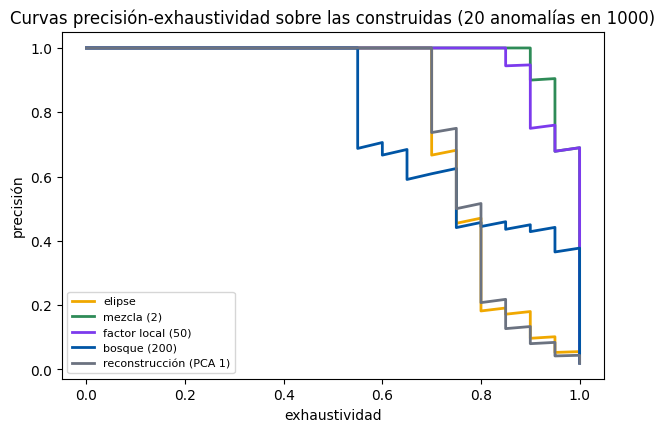

Agentes, sin etiquetas · correlación de rangos (Spearman) entre los puntajes de los seis métodos:


,elipse,mezcla,factor local,bosque,one-class SVM,reconstrucción (PCA 3)
elipse,1.00,0.92,0.87,0.77,0.15,0.60
mezcla,0.92,1.00,0.84,0.72,0.15,0.57
factor local,0.87,0.84,1.00,0.82,0.30,0.68
bosque,0.77,0.72,0.82,1.00,0.56,0.67
one-class SVM,0.15,0.15,0.30,0.56,1.00,0.47
reconstrucción (PCA 3),0.60,0.57,0.68,0.67,0.47,1.00


Cuántos de los 17 más raros (2 %) comparten cada par de métodos:


,elipse,mezcla,factor local,bosque,one-class SVM,reconstrucción (PCA 3)
elipse,17,10,10,9,4,10
mezcla,10,17,11,10,4,10
factor local,10,11,17,11,3,12
bosque,9,10,11,17,2,8
one-class SVM,4,4,3,2,17,2
reconstrucción (PCA 3),10,10,12,8,2,17


In [10]:
def error_reconstruccion(X_, n_componentes):
    pca = PCA(n_components=n_componentes).fit(X_); return -np.linalg.norm(X_ - pca.inverse_transform(pca.transform(X_)), axis=1)   # negativo: más bajo, más raro, como los demás
metodos = {"elipse": EllipticEnvelope(random_state=2026).fit(X2).score_samples(X2), "mezcla (2)": log_densidad, "factor local (50)": lof2.negative_outlier_factor_,
           "bosque (200)": puntaje_bosque, "reconstrucción (PCA 1)": error_reconstruccion(X2, 1)}
filas = []
for n, p in metodos.items():
    m = p < np.percentile(p, 2)
    filas.append({"método": n, "AUC": roc_auc_score(y2, -p), "precisión media": average_precision_score(y2, -p), "precisión al 2 %": precision_score(y2, m), "exhaustividad al 2 %": recall_score(y2, m)})
display(pd.DataFrame(filas).set_index("método").round(3))
fig, ax = plt.subplots(figsize=(7, 4.5))
for (n, p), color in zip(metodos.items(), [AMBAR, VERDE, VIOLETA, AZUL, GRIS]):
    pr, rc, _ = precision_recall_curve(y2, -p); ax.plot(rc, pr, color=color, lw=2, label=n)
ax.set_xlabel("exhaustividad"); ax.set_ylabel("precisión"); ax.legend(fontsize=8); ax.set_title("Curvas precisión-exhaustividad sobre las construidas (20 anomalías en 1000)")
plt.show()
puntajes_agentes = pd.DataFrame({"elipse": puntajes["elipse"], "mezcla": puntaje_mezcla, "factor local": puntaje_lof, "bosque": puntaje_bosque_agentes, "one-class SVM": OneClassSVM(nu=0.02).fit(Z).score_samples(Z), "reconstrucción (PCA 3)": error_reconstruccion(Z, 3)}, index=perfiles.index)
print("Agentes, sin etiquetas · correlación de rangos (Spearman) entre los puntajes de los seis métodos:"); display(puntajes_agentes.corr(method="spearman").round(2))
top_agentes = {n: set(np.argsort(puntajes_agentes[n].to_numpy())[:RAROS]) for n in puntajes_agentes.columns}
coincidencias = pd.DataFrame([[len(top_agentes[a] & top_agentes[b]) for b in puntajes_agentes.columns] for a in puntajes_agentes.columns], index=puntajes_agentes.columns, columns=puntajes_agentes.columns)
print(f"Cuántos de los {RAROS} más raros (2 %) comparten cada par de métodos:"); display(coincidencias)

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sobre las nubes, los números son los de la cátedra. Sobre los agentes, los cuatro de densidad y aislamiento tienen puntajes muy correlacionados (los mismos agentes están en el borde para todos) y comparten buena parte de sus 17 más raros. Los que menos coinciden son el one-class SVM (entrenado con nu = 0,02, dibuja una frontera muy ajustada y ordena distinto el interior) y la reconstrucción por PCA, que mide otra cosa: la distancia al plano principal; un agente puede estar lejos del centro pero sobre ese plano.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">D · Cuál para qué</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La tabla de la diapositiva, con lo que salió acá</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Elipse</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Limpiar un conjunto que es una sola gaussiana. Con dos nubes marca normales del borde y deja pasar anomalías entre ellas. Sobre los agentes, marca lo lejano del centro en cualquier dirección, y ve lo raro de una relación (el agente volátil sin caídas).</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Mezcla gaussiana</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Lo normal en varias nubes elipsoidales: el 2 % de menor log-densidad. Pide cuántas gaussianas (BIC).</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Factor local</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Densidad por zona, contra la de los vecinos: el DBSCAN de las anomalías. Pide k vecinos y una distancia; no tiene predict salvo con novelty=True.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Bosque de aislamiento</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Alta dimensión y eficiencia, sin distancias ni centros. contamination="auto" no es una proporción.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">One-class SVM</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Novedad con pocas filas y entrenamiento limpio; nu acota la fracción de atípicos. No escala; sobre los agentes es el que menos coincide con los demás (correlación de rangos 0,15 a 0,56).</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Reconstrucción</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Reducir y reconstruir: lo raro se reconstruye peor. Mide la distancia al subespacio principal; coincide menos con los demás. Es la base de los autocodificadores.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los agentes</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Sin etiquetas no hay ganador. Los de densidad y aislamiento coinciden en los extremos y discrepan en el borde; los raros por consenso están en el ruido de DBSCAN de la clase 43. Se mira el consenso, y se miran los casos (E).</td></tr></table></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">E · Usarlo: los agentes más raros por consenso, y dos agentes nuevos</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Los diez agentes más raros, por consenso</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El rango de cada agente en cada método (1 = el más raro), promediado; los diez de menor rango promedio, con su perfil traducido, cuántos métodos los ponen en su 2 %, si DBSCAN los dejó como ruido, y en qué columnas son extremos. Es la lista que se le daría a quien tiene que revisar casos: raros, no errores.</p></div>

In [11]:
rangos = puntajes_agentes.rank()                                                              # 1 = el puntaje más bajo = el más raro
consenso = rangos.mean(axis=1); en_top = pd.Series([sum(i in t for t in top_agentes.values()) for i in range(N)], index=perfiles.index)
diez = consenso.nsmallest(10).index
p_ = perfiles.loc[diez]
tabla = pd.DataFrame({"rango promedio": consenso[diez].round(1), "métodos que lo marcan (de 6)": en_top[diez], "tarifa": tarifa[diez],
                      "MWh/mes": (10 ** p_["log_tamano"]).round(0), "verano / invierno": (2 ** p_["estacionalidad"]).round(2), "variación mensual (%)": (p_["volatilidad"] * 100).round(1),
                      "crecimiento anual (%)": ((10 ** p_["tendencia_anual"] - 1) * 100).round(1), "meses con caída fuerte (%)": (p_["frac_caidas"] * 100).round(0), "cv": p_["cv"].round(2),
                      "ruido DBSCAN": np.where(ruido[[perfiles.index.get_loc(s) for s in diez]], "sí", "no")})
tabla.index.name = "serie"; display(tabla)
for s in diez[:5]:
    extremos = [f"{c_} {perfiles.loc[s, c_]:.2f} (percentil {100 * (perfiles[c_] < perfiles.loc[s, c_]).mean():.0f})" for c_ in COLUMNAS
                if (perfiles[c_] < perfiles.loc[s, c_]).mean() > 0.97 or (perfiles[c_] < perfiles.loc[s, c_]).mean() < 0.03]
    print(f"{s}: " + (" · ".join(extremos) if extremos else "extremo en la combinación, no en una columna sola"))
mejores = consenso.nsmallest(RAROS).index
print(f"Agentes en el 2 % más raro de al menos cuatro de los seis métodos: {int((en_top >= 4).sum())} · de los {RAROS} de mejor consenso, {int(ruido[[perfiles.index.get_loc(s) for s in mejores]].sum())} están en el ruido de DBSCAN de la clase 43.")

,rango promedio,métodos que lo marcan (de 6),tarifa,MWh/mes,verano / invierno,variación mensual (%),crecimiento anual (%),meses con caída fuerte (%),cv,ruido DBSCAN
serie,,,,,,,,,,
SHELDSCA | GUMAS/AUTOGENERADORES,2.3,6,Industrial/Comercial Grande,561.0,0.59,98.8,-54.8,44.0,1.87,sí
YPFTREUZ | GUMAS/AUTOGENERADORES,7.2,5,Industrial/Comercial Grande,1042.0,1.60,80.0,1370.9,32.0,1.50,sí
YPF-SPRZ | GUMAS/AUTOGENERADORES,9.0,5,Industrial/Comercial Grande,1274.0,0.96,65.7,483.6,41.0,1.46,sí
EMACHIJZ | GUMAS/AUTOGENERADORES,11.7,5,Industrial/Comercial Grande,2929.0,0.86,27.3,-86.7,52.0,1.34,sí
IRTABAAA | GUMAS/AUTOGENERADORES,13.0,5,Industrial/Comercial Grande,612.0,5.97,74.3,-18.1,39.0,0.89,sí
CRANCH3W | TARIFA USUARIO NO RESIDENCIAL >=300KWH,14.7,4,Industrial/Comercial Grande,42.0,1.40,4.0,-57.7,14.0,1.89,sí
ROUSSTOY | GUMAS/AUTOGENERADORES,16.2,4,Industrial/Comercial Grande,744.0,1.15,4.8,-88.2,21.0,0.85,sí
BOPPCA1Y | GUMAS/AUTOGENERADORES,17.0,4,Industrial/Comercial Grande,462.0,1.02,15.0,-90.7,39.0,1.23,sí
EPECORXD | TARIFA BASE ELECTRODEPENDIENTES,17.0,3,Residencial,131.0,1.43,27.0,787.7,17.0,1.10,sí


SHELDSCA | GUMAS/AUTOGENERADORES: estacionalidad -0.77 (percentil 2) · volatilidad 0.99 (percentil 100) · tendencia_anual -0.35 (percentil 2) · frac_caidas 0.44 (percentil 99) · cv 1.87 (percentil 100)
YPFTREUZ | GUMAS/AUTOGENERADORES: volatilidad 0.80 (percentil 100) · tendencia_anual 1.17 (percentil 100) · cv 1.50 (percentil 100)
YPF-SPRZ | GUMAS/AUTOGENERADORES: volatilidad 0.66 (percentil 99) · tendencia_anual 0.77 (percentil 100) · frac_caidas 0.41 (percentil 99) · cv 1.46 (percentil 99)
EMACHIJZ | GUMAS/AUTOGENERADORES: tendencia_anual -0.88 (percentil 0) · frac_caidas 0.52 (percentil 100) · cv 1.34 (percentil 99)
IRTABAAA | GUMAS/AUTOGENERADORES: estacionalidad 2.58 (percentil 100) · volatilidad 0.74 (percentil 100) · frac_caidas 0.39 (percentil 98) · cv 0.89 (percentil 98)
Agentes en el 2 % más raro de al menos cuatro de los seis métodos: 11 · de los 17 de mejor consenso, 17 están en el ruido de DBSCAN de la clase 43.


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Dos agentes nuevos: ¿son novedad?</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El comercio típico y el extremo por los detectores entrenados sobre los agentes (atípicos) y sobre el conjunto limpio (novedad): el puntaje de cada uno y en qué percentil de los 868 cae.</p></div>

In [12]:
detectores = {"elipse": EllipticEnvelope(random_state=2026).fit(Z), "mezcla": mezcla_socios, "factor local (novedad, limpio)": lof_novedad, "bosque": bosque_agentes, "one-class SVM (novedad, limpio)": ocsvm}
filas = []
for n, d in detectores.items():
    ref = d.score_samples(Z); p = d.score_samples(z_nuevos)
    veredicto = int(d.predict(z_nuevos[[1]])[0]) if n != "mezcla" else (-1 if p[1] < np.percentile(ref, 2) else 1)      # la mezcla no tiene predict de anomalía: se corta por percentil
    filas.append({"detector": n, "comercio típico: puntaje": p[0], f"comercio típico: percentil entre los {N}": (ref < p[0]).mean() * 100, "extremo: puntaje": p[1], "extremo: percentil": (ref < p[1]).mean() * 100, "extremo: veredicto (−1 raro)": veredicto})
resultado = pd.DataFrame(filas).set_index("detector"); display(resultado.round(2))
print(f"Comercio típico (800 MWh/mes, 40 % más en verano, variación de 12 %): percentiles entre {resultado[f'comercio típico: percentil entre los {N}'].min():.0f} y {resultado[f'comercio típico: percentil entre los {N}'].max():.0f}: normal para todos.")
print(f"Extremo (300 MWh/mes, más del triple en verano, variación de 45 %, cae 30 % por año): percentiles entre {resultado['extremo: percentil'].min():.1f} y {resultado['extremo: percentil'].max():.1f}. Muy raro para todos, pero no el más raro de los {N}: hay agentes reales más extremos (la tabla de arriba), y con un umbral del 2 % algunos detectores lo dejan en el borde.")
print("Qué hacer con él no lo dice el modelo: lo dice el costo de equivocarse (revisar su medición cuesta poco; planificar el despacho sin mirarlo puede costar más).")

,comercio típico: puntaje,comercio típico: percentil entre los 868,extremo: puntaje,extremo: percentil,extremo: veredicto (−1 raro)
detector,,,,,
elipse,-7.37,55.65,-575.31,3.46,-1
mezcla,-4.14,43.78,-13.90,2.76,1
"factor local (novedad, limpio)",-1.05,63.48,-2.17,2.76,-1
bosque,-0.37,69.93,-0.68,0.92,-1
"one-class SVM (novedad, limpio)",0.86,71.20,0.17,1.96,-1


Comercio típico (800 MWh/mes, 40 % más en verano, variación de 12 %): percentiles entre 44 y 71: normal para todos.
Extremo (300 MWh/mes, más del triple en verano, variación de 45 %, cae 30 % por año): percentiles entre 0.9 y 3.5. Muy raro para todos, pero no el más raro de los 868: hay agentes reales más extremos (la tabla de arriba), y con un umbral del 2 % algunos detectores lo dejan en el borde.
Qué hacer con él no lo dice el modelo: lo dice el costo de equivocarse (revisar su medición cuesta poco; planificar el despacho sin mirarlo puede costar más).


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">G · Qué quedó</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Un detector de anomalías aprende qué es lo normal y <b>puntúa</b> cuánto se aleja cada fila; el <b>umbral</b> lo pone la proporción de raros que se espera o el costo de cada error, no la biblioteca. Un umbral por columna ya es un estimador, y no alcanza: el agente volátil y sin caídas está dentro del rango de cada columna y fuera de la relación; la elipse lo ve, y falla cuando lo normal no es una sola nube.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Atípicos</b> (fit_predict sobre los mismos datos) y <b>novedad</b> (fit sobre lo limpio, predict sobre lo nuevo).</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Por densidad</b>: la mezcla de gaussianas, el factor local y el ruido de DBSCAN, que ya era anomalía. <b>Por aislamiento</b>: lo raro se aísla en pocos cortes al azar.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Evaluar</b>: con etiquetas, como un clasificador (en las construidas, los mismos números que la cátedra). Sin etiquetas, que es lo habitual, el consenso entre métodos. Los agentes más raros por consenso son grandes usuarios muy volátiles y variables, y casi todos ya eran ruido de DBSCAN en la clase 43: agrupar y detectar son la misma mirada sobre la densidad, con la pregunta al revés.</p></div>